# 03 · Validación y ajuste de hiperparámetros

En este notebook definimos cómo vamos a entrenar, ajustar y comparar todos los modelos (los base y los ensembles). La idea es que todos usen la misma partición, las mismas métricas y el mismo criterio para elegir hiperparámetros, para que los resultados se puedan comparar entre sí.

El código está en `src/validacion.py` y aquí lo probamos con una regresión logística sobre las 12 configuraciones de preprocesamiento del notebook 02.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict

sys.path.append(str(Path.cwd().parent))
from src.config import SEED, RESULTS_DIR, CLASS_NAMES, CV_FOLDS, TEST_SIZE
from src.validacion import (cargar_datos, dividir_train_test, particiones_cv, METRICAS,
                            METRICA_REFIT, ajustar_modelo, mejor_configuracion,
                            pipeline_desde_fila, comparar_modelos, guardar_tabla)

## 1. Partición train/test

Separamos un 20 % de los pacientes como test, de forma estratificada para que tenga la misma proporción de clases que el total. Este test no se usa para nada hasta el final, cuando ya tengamos elegidos los modelos. Es la misma partición que en el notebook 02 (misma semilla y tamaño).

In [2]:
X, y = cargar_datos()
X_train, X_test, y_train, y_test = dividir_train_test(X, y)

print("Train:", X_train.shape, " Test:", X_test.shape)
pd.DataFrame({"train (%)": y_train.value_counts(normalize=True).sort_index() * 100,
              "test (%)": y_test.value_counts(normalize=True).sort_index() * 100}).round(1)

Train: (1803, 27)  Test: (451, 27)


,train (%),test (%)
riesgo_cardiovascular,,
0,50.0,50.1
1,30.0,29.9
2,20.0,20.0


## 2. Esquema de validación

Con el 80 % de train hacemos validación cruzada estratificada de 5 particiones (`StratifiedKFold`). Lo hacemos así por estas razones:

- Con un solo hold-out el resultado depende mucho de qué pacientes caigan en validación. Con 5 particiones cada paciente se usa una vez para validar y tenemos media y desviación.
- Es estratificada porque las clases están desbalanceadas. Así cada partición tiene unos 72 pacientes de riesgo alto.
- Leave-one-out sería demasiado lento con 12 configuraciones y varios modelos, y la validación cruzada anidada también. Por eso separamos el test al principio y lo dejamos para la evaluación final.

Para cada modelo y cada una de las 12 configuraciones de preprocesamiento hacemos un `GridSearchCV` (o `RandomizedSearchCV` si la rejilla es muy grande). Así evaluamos todas las combinaciones modelo × preprocesamiento, que es lo que pide el enunciado.

Como todo el preprocesamiento está dentro del pipeline, en cada partición la imputación, el escalado y SMOTE-NC se ajustan solo con el train de esa partición. La validación se hace siempre con pacientes reales. Esto es lo que nos aclaró la profesora en el anuncio del 13/11: en validación cruzada SMOTE va en el train de cada fold, y para el modelo final se aplica sobre todo el train y se evalúa en el test inicial.

### Comprobación de que SMOTE solo se aplica en el train de cada partición

Usamos un clasificador de prueba que solo apunta cuántos pacientes recibe al entrenar y al predecir.

In [3]:
registro = []

class Contador(BaseEstimator, ClassifierMixin):
    # no aprende nada, solo guarda cuántas filas le llegan
    def __init__(self, a=1):
        self.a = a
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        registro.append(("entrenar", len(X), np.bincount(np.asarray(y, int)).tolist()))
        return self
    def predict(self, X):
        registro.append(("predecir", len(X), None))
        return np.zeros(len(X), dtype=int)

ajustar_modelo("contador", Contador(), {"a": [1]}, X_train, y_train, n_jobs=1, verbose=False,
               configuraciones=[{"imputacion": "mediana", "escalado": "estandar", "balanceo": "smotenc"}])

tam_folds = [(len(tr), len(va), np.bincount(y_train.iloc[tr]).tolist())
             for tr, va in particiones_cv().split(X_train, y_train)]
pd.DataFrame({"train original": [t[2] for t in tam_folds],
              "train tras SMOTE-NC": [r[2] for r in registro if r[0] == "entrenar"][:CV_FOLDS],
              "pacientes en validación": [t[1] for t in tam_folds],
              "predicciones": [r[1] for r in registro if r[0] == "predecir"][0::2]})

,train original,train tras SMOTE-NC,pacientes en validación,predicciones
0,"[721, 432, 289]","[721, 721, 721]",361,361
1,"[721, 433, 288]","[721, 721, 721]",361,361
2,"[720, 433, 289]","[720, 720, 720]",361,361
3,"[721, 433, 289]","[721, 721, 721]",360,360
4,"[721, 433, 289]","[721, 721, 721]",360,360


En cada partición SMOTE-NC iguala las tres clases del train, pero el número de predicciones coincide con los pacientes de validación. Es decir, la validación se hace sin pacientes sintéticos.

## 3. Métricas

Guardamos cuatro métricas en todas las búsquedas:

- **F1 macro**: media del F1 de las tres clases. Es la que usamos para elegir los hiperparámetros (`refit`).
- **Balanced accuracy**: media del recall de las tres clases. No le afecta el desbalanceo.
- **Recall de riesgo alto**: de los pacientes que de verdad tienen riesgo alto, cuántos detecta el modelo.
- **Accuracy**: la dejamos como referencia, pero con clases 50/30/20 un modelo que diga siempre "bajo" ya saca un 50 %.

### Qué métrica es más importante desde el punto de vista clínico

El peor error es decir que un paciente de riesgo alto tiene riesgo bajo o moderado, porque se quedaría sin seguimiento ni tratamiento preventivo y puede acabar teniendo un evento cardiovascular. El error contrario (un falso riesgo alto) supone más pruebas o consultas, que cuesta dinero pero no pone en peligro al paciente. Por eso la métrica más crítica para nosotros es el **recall de la clase de riesgo alto**.

Aun así no elegimos los hiperparámetros solo con ella, porque un modelo que diga "alto" a todo el mundo tendría recall 1 y no serviría para nada. Elegimos con F1 macro, que obliga a hacerlo bien en las tres clases, y luego miramos el recall de riesgo alto para comparar los modelos y decidir entre los que estén parecidos.

## 4. Prueba con regresión logística

Probamos todo el esquema con una regresión logística, ajustando la regularización `C`, en las 12 configuraciones. La columna `sobreajuste` es la diferencia de F1 macro entre train y validación.

In [4]:
tabla, busquedas = ajustar_modelo("logistica", LogisticRegression(max_iter=3000),
                                  {"C": [0.01, 0.1, 1, 10]}, X_train, y_train)
guardar_tabla(tabla, "validacion_logistica")
tabla[["imputacion", "escalado", "balanceo", "mejores_parametros", "f1_macro_media", "f1_macro_std",
       "recall_alto_media", "bal_acc_media", "accuracy_media", "sobreajuste"]].round(3)

logistica | mediana-estandar-ninguno         F1 macro 0.638 (±0.027)  recall alto 0.659  [3 s]
logistica | mediana-estandar-class_weight    F1 macro 0.631 (±0.025)  recall alto 0.748  [0 s]


logistica | mediana-estandar-smotenc         F1 macro 0.623 (±0.023)  recall alto 0.723  [0 s]


logistica | mediana-yeojohnson-ninguno       F1 macro 0.642 (±0.035)  recall alto 0.670  [0 s]


logistica | mediana-yeojohnson-class_weight  F1 macro 0.638 (±0.028)  recall alto 0.759  [0 s]


logistica | mediana-yeojohnson-smotenc       F1 macro 0.632 (±0.020)  recall alto 0.726  [1 s]


logistica | knn-estandar-ninguno             F1 macro 0.636 (±0.029)  recall alto 0.659  [0 s]


... (2 outputs left out)

logistica | knn-yeojohnson-ninguno           F1 macro 0.643 (±0.031)  recall alto 0.662  [1 s]


logistica | knn-yeojohnson-class_weight      F1 macro 0.639 (±0.033)  recall alto 0.748  [0 s]


logistica | knn-yeojohnson-smotenc           F1 macro 0.631 (±0.021)  recall alto 0.715  [1 s]


,imputacion,escalado,balanceo,mejores_parametros,f1_macro_media,f1_macro_std,recall_alto_media,bal_acc_media,accuracy_media,sobreajuste
0,knn,yeojohnson,ninguno,{'C': 0.1},0.643,0.031,0.662,0.641,0.681,0.021
1,mediana,yeojohnson,ninguno,{'C': 10},0.642,0.035,0.670,0.642,0.678,0.026
2,knn,yeojohnson,class_weight,{'C': 1},0.639,0.033,0.748,0.651,0.658,0.031
3,mediana,estandar,ninguno,{'C': 1},0.638,0.027,0.659,0.636,0.673,0.020
4,mediana,yeojohnson,class_weight,{'C': 0.1},0.638,0.028,0.759,0.652,0.657,0.026
5,knn,estandar,ninguno,{'C': 1},0.636,0.029,0.659,0.634,0.673,0.021
6,knn,estandar,class_weight,{'C': 10},0.633,0.031,0.737,0.645,0.653,0.031
7,mediana,yeojohnson,smotenc,{'C': 1},0.632,0.020,0.726,0.642,0.650,0.032
8,knn,yeojohnson,smotenc,{'C': 10},0.631,0.021,0.715,0.640,0.651,0.031
9,mediana,estandar,class_weight,{'C': 0.1},0.631,0.025,0.748,0.645,0.653,0.031


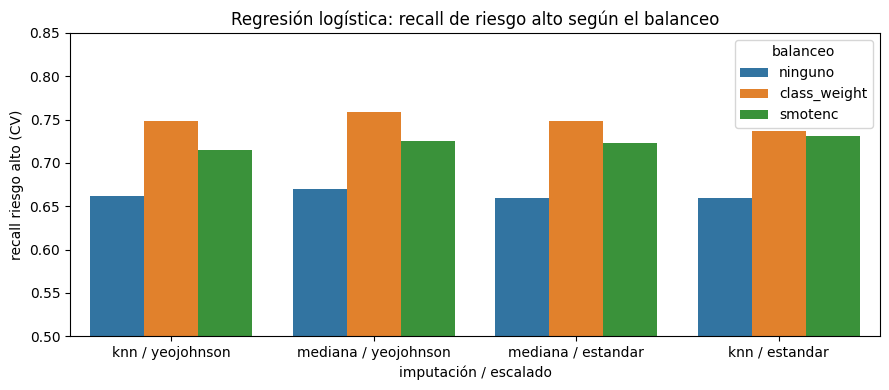

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
orden = tabla.assign(conf=tabla.imputacion + " / " + tabla.escalado)
sns.barplot(data=orden, x="conf", y="recall_alto_media", hue="balanceo", ax=ax)
ax.set_xlabel("imputación / escalado")
ax.set_ylabel("recall riesgo alto (CV)")
ax.set_ylim(0.5, 0.85)
ax.set_title("Regresión logística: recall de riesgo alto según el balanceo")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "validacion_logistica_recall_alto.png", dpi=150)
plt.show()

Con la logística las diferencias de F1 macro entre configuraciones son pequeñas (todas entre 0,62 y 0,64). Donde sí se nota el preprocesamiento es en el recall de riesgo alto: sin balancear se queda en torno a 0,66 y con `class_weight` o SMOTE-NC sube a 0,71-0,76. Por eso no vamos a mirar solo el F1 macro al comparar.

## 5. Matriz de confusión en validación cruzada

Para ver en qué se equivoca el mejor ajuste sin tocar el test, sacamos las predicciones de validación cruzada (`cross_val_predict`): cada paciente de train se predice con el modelo entrenado en las otras 4 particiones.

Mejor configuración: knn yeojohnson ninguno {'C': 0.1}


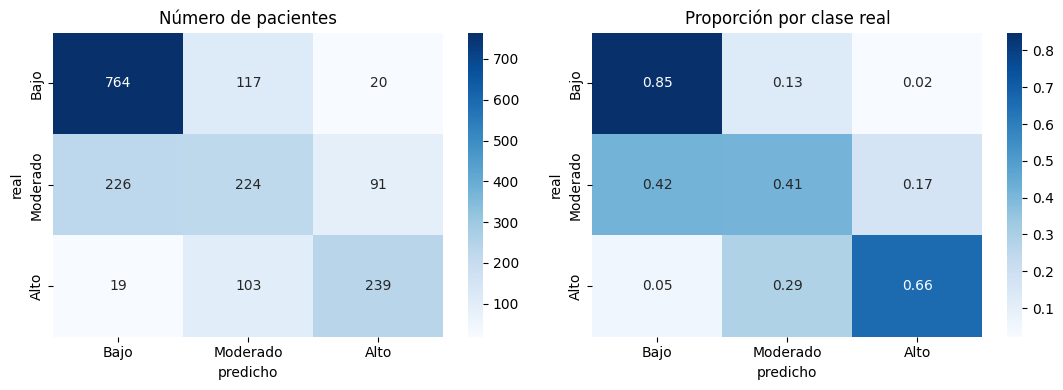

In [6]:
mejor = mejor_configuracion(tabla)
print("Mejor configuración:", mejor.imputacion, mejor.escalado, mejor.balanceo, mejor.mejores_parametros)

pipe, _ = pipeline_desde_fila(LogisticRegression(max_iter=3000), mejor)
pred_cv = cross_val_predict(pipe, X_train, y_train, cv=particiones_cv(), n_jobs=-1)

nombres = [CLASS_NAMES[c] for c in sorted(CLASS_NAMES)]
matriz = confusion_matrix(y_train, pred_cv, labels=sorted(CLASS_NAMES))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=nombres, yticklabels=nombres, ax=axes[0])
axes[0].set_title("Número de pacientes")
sns.heatmap(matriz / matriz.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=nombres, yticklabels=nombres, ax=axes[1])
axes[1].set_title("Proporción por clase real")
for ax in axes:
    ax.set_xlabel("predicho")
    ax.set_ylabel("real")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "matriz_confusion_cv_logistica.png", dpi=150)
plt.show()

La clase que peor se predice es la de riesgo moderado, que se confunde con las otras dos porque está en medio. Los pacientes de riesgo alto que fallan casi siempre se van a moderado y muy pocos a bajo, que sería el error más grave.

## 6. Comparación entre modelos

Para comparar los mejores modelos al final (y para los tests estadísticos opcionales) repetimos la validación cruzada de 5 particiones 3 veces con la misma semilla, así todos los modelos se evalúan exactamente con las mismas particiones (15 resultados emparejados por modelo). Como ejemplo comparamos la mejor logística sin balanceo con la mejor con `class_weight`.

In [7]:
sin_balanceo = tabla[tabla.balanceo == "ninguno"].iloc[0]
con_pesos = tabla[tabla.balanceo == "class_weight"].iloc[0]
comparacion = comparar_modelos({
    "logística sin balanceo": (LogisticRegression(max_iter=3000), sin_balanceo),
    "logística class_weight": (LogisticRegression(max_iter=3000), con_pesos),
}, X_train, y_train)
comparacion.groupby("modelo")[list(METRICAS)].agg(["mean", "std"]).round(3)

f1_macro        bal_acc        recall_alto         \
                           mean    std    mean    std        mean    std   
modelo                                                                     
logística class_weight    0.640  0.026   0.653  0.029       0.753  0.057   
logística sin balanceo    0.641  0.029   0.641  0.029       0.670  0.052   

                       accuracy         
                           mean    std  
modelo                                  
logística class_weight     0.66  0.021  
logística sin balanceo     0.68  0.025

Con `class_weight` el F1 macro casi no cambia pero el recall de riesgo alto sube bastante, a costa de algo de accuracy. Es el tipo de compromiso que tendremos que discutir en las conclusiones.